# Laboratorio 4 - Segmentación de imágenes

## Actividad 1: pipeline de preparación y representación

Aunque las carpetas contienen el conjunto completo de 900 imágenes de ISIC 2016, este laboratorio utiliza únicamente las 20 imágenes indicadas en el enunciado: 15 para ajuste y 5 para prueba. Las máscaras de referencia se reservan para evaluar las máscaras estimadas; no se utilizan para construir la representación de los píxeles.

In [13]:

from pathlib import Path

# NumPy representa las imágenes y las características como arreglos numéricos.
import numpy as np
import matplotlib.pyplot as plt
# Pillow se utiliza para leer las imágenes y las máscaras.
from PIL import Image
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer

# Se intenta trabajar desde la carpeta del notebook; el segundo caso permite
# ejecutar esta celda desde la raíz del repositorio.
RUTA_LAB = Path.cwd()
if not (RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data").is_dir():
    RUTA_LAB = RUTA_LAB / "202620" / "Laboratorios" / "L4"
RUTA_IMAGENES = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_Data"
RUTA_MASCARAS = RUTA_LAB / "ISBI2016_ISIC_Part1_Training_GroundTruth"

# Se reduce la resolución para que K-medias sea ejecutable.
# Pillow expresa el tamaño como (ancho, alto).
TAMANO_IMAGEN = (256, 256)

# Estas 15 imágenes se usan para explorar y seleccionar la configuración.
IDS_AJUSTE = [
    "ISIC_0000085", "ISIC_0000086", "ISIC_0000089", "ISIC_0000094",
    "ISIC_0000108", "ISIC_0000114", "ISIC_0000116", "ISIC_0000122",
    "ISIC_0000133", "ISIC_0000137", "ISIC_0000150", "ISIC_0000153",
    "ISIC_0000156", "ISIC_0000157", "ISIC_0000112",
]
# Estas 5 imágenes se reservan para la evaluación final.
IDS_PRUEBA = [
    "ISIC_0000087", "ISIC_0000105", "ISIC_0000110", "ISIC_0000123",
    "ISIC_0000128",
]
# La lista completa permite verificar las 20 parejas imagen-máscara.
IDS_USADOS = IDS_AJUSTE + IDS_PRUEBA




## Carga y preparación de imágenes y máscaras

Los canales RGB y las coordenadas se normalizan a `[0, 1]`. Las máscaras se convierten de `0/255` a `0/1`. Si fuera necesario redimensionar una máscara, se utiliza vecino más cercano para conservar su naturaleza binaria.

In [14]:
# Construye la ruta de la imagen a partir de su identificador ISIC.
def ruta_imagen(image_id):
    return RUTA_IMAGENES / f"{image_id}.jpg"


# Las máscaras tienen el mismo identificador y el sufijo _Segmentation.
def ruta_mascara(image_id):
    return RUTA_MASCARAS / f"{image_id}_Segmentation.png"


def cargar_imagen(image_id, tamano=TAMANO_IMAGEN):
    """Carga una imagen RGB y la redimensiona al tamaño indicado."""
    # Se informa explícitamente si falta un archivo seleccionado.
    ruta = ruta_imagen(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la imagen: {ruta}")
    # Convertir a RGB garantiza tres canales aunque el archivo tenga otro modo.
    with Image.open(ruta) as imagen:
        imagen = imagen.convert("RGB")
        if tamano is not None and imagen.size != tamano:
            imagen = imagen.resize(tamano, resample=Image.Resampling.LANCZOS)
        return np.asarray(imagen)


def cargar_mascara(image_id, tamano=None):
    """Carga, redimensiona opcionalmente y binariza la máscara de referencia."""
    ruta = ruta_mascara(image_id)
    if not ruta.is_file():
        raise FileNotFoundError(f"No se encontró la máscara: {ruta}")
    
    # L convierte la máscara a escala de grises, con un único canal.
    with Image.open(ruta) as mascara:
        mascara = mascara.convert("L")
        # El vecino más cercano conserva los valores discretos de la máscara.
        if tamano is not None and mascara.size != tamano:
            mascara = mascara.resize(tamano, resample=Image.Resampling.NEAREST)
        valores = np.asarray(mascara)

    # Convierte los valores originales 0/255 en etiquetas binarias 0/1.
    return (valores > 0).astype(np.uint8)


def validar_pares(image_ids):
    """Verifica que cada imagen seleccionada tenga su máscara correspondiente."""
    # La máscara solo se valida aquí; no participa en la representación de X.
    for image_id in image_ids:
        imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
        mascara = cargar_mascara(image_id, tamano=TAMANO_IMAGEN)
        if imagen.shape[:2] != mascara.shape:
            raise ValueError(f"Dimensiones incompatibles para {image_id}")
        if not np.isin(mascara, [0, 1]).all():
            raise ValueError(f"La máscara de {image_id} no es binaria")


validar_pares(IDS_USADOS)
print(f"Pares imagen-máscara validados: {len(IDS_USADOS)}")
print(f"Imágenes de ajuste: {len(IDS_AJUSTE)} | Imágenes de prueba: {len(IDS_PRUEBA)}")


Pares imagen-máscara validados: 20
Imágenes de ajuste: 15 | Imágenes de prueba: 5


## Representación `[beta·R, beta·G, beta·B, lambda·x, lambda·y]`

Cada fila de la matriz representa un píxel. `x` aumenta de izquierda a derecha y `y` aumenta de arriba hacia abajo. La función conserva por separado la forma `(H, W)` de la imagen para poder reconstruir posteriormente las etiquetas de K-medias como una máscara.

In [15]:
def representar_imagen(imagen, beta=1.0, lambda_=1.0):
    """Construye una matriz de características con una fila por píxel."""
    imagen = np.asarray(imagen)
    if imagen.ndim != 3 or imagen.shape[2] != 3:
        raise ValueError("La imagen debe tener forma (alto, ancho, 3)")
    if beta < 0 or lambda_ < 0 or (beta == 0 and lambda_ == 0):
        raise ValueError("beta y lambda deben ser no negativos y no ambos cero")

    alto, ancho, _ = imagen.shape
    # Los canales RGB pasan de [0, 255] a [0, 1].
    colores = imagen.astype(np.float32) / 255.0
    # x representa columnas y y representa filas, ambas normalizadas a [0, 1].
    x = np.linspace(0.0, 1.0, ancho, dtype=np.float32)
    y = np.linspace(0.0, 1.0, alto, dtype=np.float32)
    coordenada_x, coordenada_y = np.meshgrid(x, y)

    # Cada fila final corresponde a un píxel y contiene cinco características.
    caracteristicas = np.column_stack([
    # ravel aplana cada canal siguiendo el mismo orden de píxeles.
        beta * colores[:, :, 0].ravel(),
        beta * colores[:, :, 1].ravel(),
        beta * colores[:, :, 2].ravel(),
        lambda_ * coordenada_x.ravel(),
        lambda_ * coordenada_y.ravel(),
    ])
    return caracteristicas.astype(np.float32)


def crear_pipeline(beta=1.0, lambda_=1.0):
    """Crea el pipeline parametrizable solicitado en la actividad."""
    # FunctionTransformer adapta nuestra función al formato de Pipeline.
    return Pipeline([
    # K-means devuelve etiquetas en una dimensión; aquí recuperamos la imagen.
        (
            "representacion",
            FunctionTransformer(
                lambda imagen: representar_imagen(imagen, beta, lambda_),
                validate=False,
            ),
        ),
    ])


def reconstruir_mascara(etiquetas, forma):
    """Devuelve las etiquetas 1D de los píxeles con forma (alto, ancho)."""
    alto, ancho = forma
    etiquetas = np.asarray(etiquetas)
    if etiquetas.size != alto * ancho:
        raise ValueError("El número de etiquetas no coincide con la imagen")
    return etiquetas.reshape((alto, ancho))


## Verificación con una imagen de ajuste

Se prueba una configuración que combina color y posición. La matriz resultante queda lista para utilizarse como entrada de `KMeans` en la Actividad 2.

In [16]:
# Se verifica una imagen de ajuste sin consultar la máscara para construir X.
image_id = IDS_AJUSTE[0]
imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
mascara_referencia = cargar_mascara(
    image_id,
    tamano=TAMANO_IMAGEN,
)

# Esta configuración combina color y posición.
beta = 1.0
lambda_ = 0.5
pipeline = crear_pipeline(beta=beta, lambda_=lambda_)
# X será la entrada de KMeans en la Actividad 2.
X = pipeline.transform(imagen)

assert X.shape == (imagen.shape[0] * imagen.shape[1], 5)
assert mascara_referencia.shape == imagen.shape[:2]
assert np.isin(mascara_referencia, [0, 1]).all()

print(f"Imagen: {image_id}")
print(f"Dimensiones: {imagen.shape[0]} x {imagen.shape[1]}")
print(f"Matriz de representación: {X.shape}")
print(f"Rango de colores normalizados: [{imagen.min() / 255:.3f}, {imagen.max() / 255:.3f}]")
print(f"Valores de la máscara: {np.unique(mascara_referencia)}")


Imagen: ISIC_0000085
Dimensiones: 256 x 256
Matriz de representación: (65536, 5)
Rango de colores normalizados: [0.000, 0.847]
Valores de la máscara: [0 1]


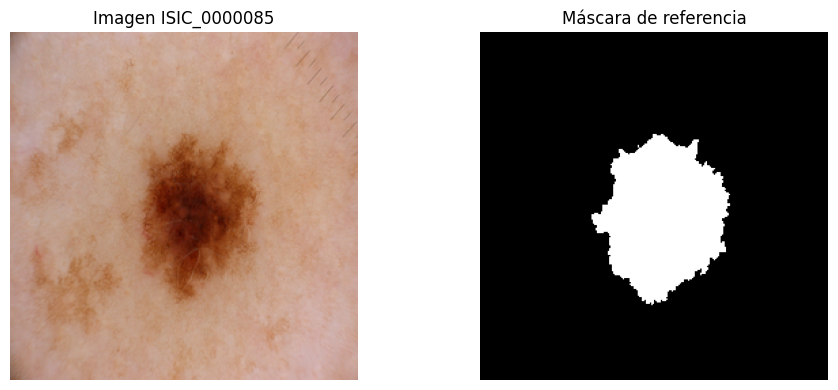

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(imagen)
axes[0].set_title(f"Imagen {image_id}")
axes[1].imshow(mascara_referencia, cmap="gray")
axes[1].set_title("Máscara de referencia")
for ax in axes:
    ax.axis("off")
plt.tight_layout()


## Actividad 2: agrupación y selección de K

Se exploran diez razones distintas entre posición y color. Para cada combinación se entrenan modelos K-medias con `K` entre 2 y 8. El coeficiente de silueta se calcula sobre una muestra reproducible de píxeles y se utiliza para seleccionar el mejor valor de `K`. Solo se usan las 15 imágenes de ajuste.

In [18]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import pandas as pd

# Las parejas (beta, lambda) tienen razones lambda/beta distintas.
# Se incluyen explícitamente los casos de solo color y solo posición.
CONFIGURACIONES = [
    {"beta": 1.0, "lambda_": 0.0, "nombre": "solo_color"},
    {"beta": 1.0, "lambda_": 0.1, "nombre": "lambda_beta_0.1"},
    {"beta": 1.0, "lambda_": 0.25, "nombre": "lambda_beta_0.25"},
    {"beta": 1.0, "lambda_": 0.5, "nombre": "lambda_beta_0.5"},
    {"beta": 1.0, "lambda_": 0.75, "nombre": "lambda_beta_0.75"},
    {"beta": 1.0, "lambda_": 1.0, "nombre": "lambda_beta_1.0"},
    {"beta": 1.0, "lambda_": 2.0, "nombre": "lambda_beta_2.0"},
    {"beta": 1.0, "lambda_": 4.0, "nombre": "lambda_beta_4.0"},
    {"beta": 1.0, "lambda_": 8.0, "nombre": "lambda_beta_8.0"},
    {"beta": 0.0, "lambda_": 1.0, "nombre": "solo_posicion"},
]
VALORES_K = range(2, 9)
TAMANO_MUESTRA_SILUETA = 5000
SEMILLA_MUESTRA = 42
SEMILLA_KMEANS = 42

def indices_muestra(n_elementos, tamano, semilla):
    """Selecciona índices sin reemplazo de forma reproducible."""
    rng = np.random.default_rng(semilla)
    cantidad = min(tamano, n_elementos)
    return rng.choice(n_elementos, size=cantidad, replace=False)


def evaluar_kmeans_imagen(image_id, configuracion):
    """Calcula la silueta para K=2,...,8 en una imagen de ajuste."""
    imagen = cargar_imagen(image_id, tamano=TAMANO_IMAGEN)
    X_imagen = crear_pipeline(
        beta=configuracion["beta"],
        lambda_=configuracion["lambda_"],
    ).transform(imagen)
    indices = indices_muestra(
        len(X_imagen), TAMANO_MUESTRA_SILUETA, SEMILLA_MUESTRA
    )
    X_muestra = X_imagen[indices]
    # Las imágenes tienen millones de píxeles; para explorar K se ajusta
    # K-means sobre la misma muestra reproducible usada por la silueta.
    X_entrenamiento = X_muestra
    resultados = []

    for k in VALORES_K:
        modelo = KMeans(
            n_clusters=k,
            random_state=SEMILLA_KMEANS,
            n_init=10,
        )
        # Se ajusta K-medias únicamente con características, sin máscaras.
        etiquetas = modelo.fit_predict(X_entrenamiento)
        silueta = silhouette_score(
            X_muestra,
            etiquetas,
            metric="euclidean",
        )
        resultados.append({
            "imagen": image_id,
            "configuracion": configuracion["nombre"],
            "beta": configuracion["beta"],
            "lambda_": configuracion["lambda_"],
            "K": k,
            "silueta": silueta,
            "muestra_silueta": len(indices),
            "semilla_muestra": SEMILLA_MUESTRA,
        })
    return resultados


In [19]:
# Se ejecuta el experimento sobre las 15 imágenes de ajuste.
resultados_actividad_2 = []
for image_id in IDS_AJUSTE:
    for configuracion in CONFIGURACIONES:
        resultados_actividad_2.extend(
            evaluar_kmeans_imagen(image_id, configuracion)
        )

tabla_silueta = pd.DataFrame(resultados_actividad_2)
mejor_k_por_imagen = (
    tabla_silueta.loc[
        tabla_silueta.groupby(["imagen", "configuracion"])["silueta"].idxmax()
    ]
    .sort_values(["configuracion", "imagen"])
    .reset_index(drop=True)
)

promedio_configuraciones = (
    mejor_k_por_imagen.groupby(
        ["configuracion", "beta", "lambda_"]
    )["silueta"]
    .mean()
    .sort_values(ascending=False)
    .rename("silueta_promedio")
    .reset_index()
)

print(f"Filas evaluadas: {len(tabla_silueta)}")
print(f"Muestra por silueta: hasta {TAMANO_MUESTRA_SILUETA} píxeles")
print(f"Semilla de muestra: {SEMILLA_MUESTRA}")
display(promedio_configuraciones)


Filas evaluadas: 1050
Muestra por silueta: hasta 5000 píxeles
Semilla de muestra: 42


,configuracion,beta,lambda_,silueta_promedio
0,solo_color,1.0,0.00,0.737515
1,lambda_beta_0.1,1.0,0.10,0.704221
2,lambda_beta_0.25,1.0,0.25,0.612231
3,lambda_beta_0.5,1.0,0.50,0.490475
4,lambda_beta_0.75,1.0,0.75,0.444762
5,lambda_beta_1.0,1.0,1.00,0.441057
6,lambda_beta_2.0,1.0,2.00,0.428080
7,solo_posicion,0.0,1.00,0.411685
8,lambda_beta_8.0,1.0,8.00,0.408397
9,lambda_beta_4.0,1.0,4.00,0.407798
